# 02. Đánh giá thuật toán nhịp tim cổ tay của firmware khi áp dụng vào dataset

- Dùng máy đo điện tim ngực (ECG) làm **Thước đo (Ground Truth)** để chấm điểm thuật toán nhịp tim cổ tay (`bvp-causal-peaks`).
- Mục tiêu: Đánh giá sai số (MAE) và kiểm tra xem thuật toán cổ tay có bị mất nhịp khi người dùng bị Stress hay không.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_colwidth', None)
here = Path.cwd().resolve()
ROOT = next((p for p in [here, *here.parents] if (p / 'ai/requirements.txt').is_file() and (p / 'backend').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Vui lòng mở notebook trong repository ASD-EASE')
sys.path.insert(0, str(ROOT / 'ai'))

REVIEW = ROOT / 'ai/data/interim/wesad/hr-ecg-review-v1'
report = json.loads((REVIEW / 'report.json').read_text(encoding='utf-8'))
print(f'Trạng thái báo cáo: {report["status"]}, Đủ 15 đối tượng: {report["all_15_subjects"]}')

Trạng thái báo cáo: COMPLETE, Đủ 15 đối tượng: True


## 1. Độ phủ và sai số theo từng trạng thái

- **MAE:** Sai số tuyệt đối trung bình so với chuẩn ECG (mong muốn < 5 bpm); **P90:** 90% số lần đo có sai số nhỏ hơn mức này.
- **Phát hiện:** Thuật toán bvp-causal-peaks bị mất tới **83,6% dữ liệu ở pha Stress** (độ phủ chỉ còn 16,4%).

,Trạng thái,Cửa sổ ECG (10s),Cửa sổ đủ HR & ECG (10s),Độ phủ nhịp tim (%),MAE (bpm),P90 (bpm),Bias (bpm)
0,Baseline (Nghỉ ngơi),17461,10962,62.81,1.57,3.46,0.15
1,Stress (Căng thẳng),9816,1595,16.40,3.34,5.54,-1.29
2,Amusement (Thư giãn),5425,3738,69.11,1.64,3.77,0.02


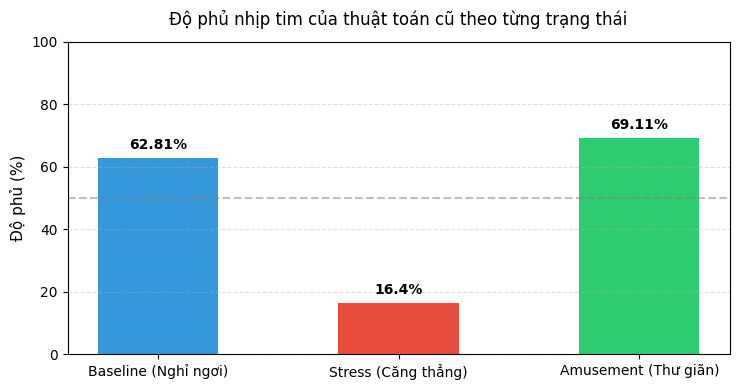

In [2]:
label_names = {'1': 'Baseline (Nghỉ ngơi)', '2': 'Stress (Căng thẳng)', '3': 'Amusement (Thư giãn)'}
rows = []
for label, name in label_names.items():
    s = report['pooled']['by_source_label'][label]
    rows.append({
        'Trạng thái': name,
        'Cửa sổ ECG (10s)': s['windows'],
        'Cửa sổ đủ HR & ECG (10s)': s['paired_windows'],
        'Độ phủ nhịp tim (%)': round(100 * s['paired_coverage_among_reference'], 2),
        'MAE (bpm)': round(s['mae_bpm'], 2),
        'P90 (bpm)': round(s['p90_absolute_error_bpm'], 2),
        'Bias (bpm)': round(s['bias_bpm'], 2)
    })

df_summary = pd.DataFrame(rows)
display(df_summary)

# Vẽ biểu đồ cột độ phủ
plt.figure(figsize=(7.5, 4))
bars = plt.bar(df_summary['Trạng thái'], df_summary['Độ phủ nhịp tim (%)'], color=['#3498DB', '#E74C3C', '#2ECC71'], width=0.5)
plt.ylabel('Độ phủ (%)', fontsize=11)
plt.ylim(0, 100)
plt.title('Độ phủ nhịp tim của thuật toán cũ theo từng trạng thái', fontsize=12, pad=12)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 2, f'{yval}%', ha='center', va='bottom', fontweight='bold')
plt.axhline(50, color='gray', linestyle='--', alpha=0.5)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

## 2. Dữ liệu nhịp tim 15 đối tượng sau áp dụng thuật toán

- Thống kê chi tiết MAE và độ phủ trên từng người (`S2` đến `S17`).

In [3]:
sub_rows = []
for p in report['subject_summaries']:
    s = p['binary_task']
    sub_rows.append({
        'Đối tượng': p['subject'],
        'Cửa sổ đủ HR & ECG (10s)': s['paired_windows'],
        'Độ phủ nhịp tim (%)': round(100 * s['paired_coverage_among_reference'], 2),
        'MAE (bpm)': round(s['mae_bpm'], 2),
        'P90 (bpm)': round(s['p90_absolute_error_bpm'], 2)
    })

df_sub = pd.DataFrame(sub_rows).set_index('Đối tượng')
display(df_sub)
print(f'Sai số trung bình toàn tập (Macro MAE): {report["macro_subject_mae_bpm"]:.2f} bpm')

,Cửa sổ đủ HR & ECG (10s),Độ phủ nhịp tim (%),MAE (bpm),P90 (bpm)
Đối tượng,,,,
S2,868,42.47,1.46,3.27
S3,830,39.17,2.45,5.28
S4,1448,67.82,1.37,3.05
S5,839,38.72,1.48,3.22
S6,1137,52.35,1.82,4.45
S7,1279,58.99,1.65,4.08
S8,1116,51.91,1.90,3.47
S9,1019,47.13,1.75,4.03
S10,1121,49.98,1.74,3.35


Sai số trung bình toàn tập (Macro MAE): 1.79 bpm


## 3. Biểu đồ nhịp tim S2

- So sánh sóng điện tim ECG (ngực) và sóng quang BVP (cổ tay) ở pha Stress.
- Quan sát trực quan dải thời gian pha Stress (phút 38 đến 48) trên chuỗi 100 phút.

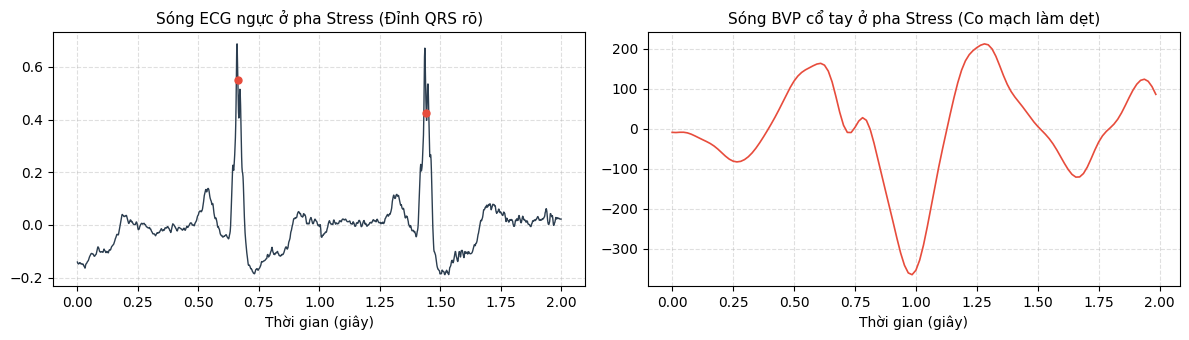

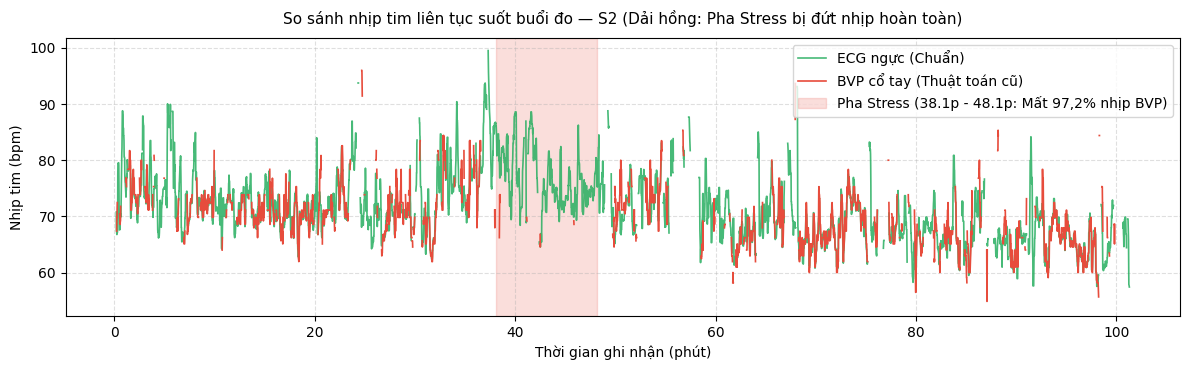

In [4]:
SUBJECT = 'S2'
with np.load(REVIEW / SUBJECT / 'review_snippets.npz', allow_pickle=False) as snippets:
    fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(12, 3.5))
    ecg = snippets['label2_ecg']
    qrs = snippets['label2_qrs']
    bvp = snippets['label2_bvp']
    
    t_ecg = np.arange(len(ecg)) / 700
    qidx = np.minimum((qrs * 700).round().astype(int), len(ecg) - 1)
    ax_l.plot(t_ecg[:1400], ecg[:1400], color='#2C3E50', lw=1.0)
    ax_l.scatter(qrs[qrs < 2.0], ecg[qidx[qrs < 2.0]], color='#E74C3C', s=25, zorder=3)
    ax_l.set_title('Sóng ECG ngực ở pha Stress (Đỉnh QRS rõ)', fontsize=11)
    ax_l.set_xlabel('Thời gian (giây)')
    ax_l.grid(True, linestyle='--', alpha=0.4)
    
    t_bvp = np.arange(len(bvp)) / 64
    ax_r.plot(t_bvp[:128], bvp[:128], color='#E74C3C', lw=1.2)
    ax_r.set_title('Sóng BVP cổ tay ở pha Stress (Co mạch làm dẹt)', fontsize=11)
    ax_r.set_xlabel('Thời gian (giây)')
    ax_r.grid(True, linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()

# Chuỗi thời gian so sánh ECG vs BVP suốt 100 phút
pairs = pd.read_csv(REVIEW / SUBJECT / 'comparison.csv')
plt.figure(figsize=(12, 3.8))
plt.plot(pairs['time_ms'] / 60000, pairs['ecg_hr_bpm'], label='ECG ngực (Chuẩn)', color='#27AE60', lw=1.2, alpha=0.85)
plt.plot(pairs['time_ms'] / 60000, pairs['ppg_hr_bpm'], label='BVP cổ tay (Thuật toán cũ)', color='#E74C3C', lw=1.2)
# Highlight dải thời gian pha Stress của S2
stress_mask = pairs['source_label_code'] == 2
t_s_min = pairs.loc[stress_mask, 'time_ms'].min() / 60000
t_s_max = pairs.loc[stress_mask, 'time_ms'].max() / 60000
plt.axvspan(t_s_min, t_s_max, color='#E74C3C', alpha=0.18, label=f'Pha Stress ({t_s_min:.1f}p - {t_s_max:.1f}p: Mất 97,2% nhịp BVP)')
plt.xlabel('Thời gian ghi nhận (phút)', fontsize=10)
plt.ylabel('Nhịp tim (bpm)', fontsize=10)
plt.title(f'So sánh nhịp tim liên tục suốt buổi đo — {SUBJECT} (Dải hồng: Pha Stress bị đứt nhịp hoàn toàn)', fontsize=11, pad=10)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()